# The EA engine: generators, operations, archive

ARIEL's evolutionary algorithm (`ariel.ec.EA`) runs a list of operations on a population once per generation and stores every individual in a SQLite database. This notebook evolves bit strings toward all ones (the *one-max* problem), the smallest problem that shows every part: a generator makes the genotypes, five operations form the pipeline, the engine runs it, and the archive reads the history back.

You will see a plot of the best fitness per generation and a table of the best individuals ever found. No graphics backend is needed.

In [1]:
# Standard library
import random
from pathlib import Path
from typing import cast

In [2]:
# Third-party libraries
import matplotlib.pyplot as plt
from rich.table import Table

In [3]:
# Local libraries
from ariel import console
from ariel.ec import (
    EA,
    Archive,
    Crossover,
    EAOperation,
    Individual,
    IntegerMutator,
    IntegersGenerator,
    Population,
)

In [4]:
# Seed, sizes and the output folder
SEED = 42
random.seed(SEED)  # shuffling in Population; the generators seed themselves
GENES = 10
POPULATION_SIZE = 20
GENERATIONS = 30
HALL_SIZE = 3
DATA = Path.cwd() / "__data__" / "ec_engine"
DATA.mkdir(parents=True, exist_ok=True)

## Individuals from a generator

An `Individual` holds a genotype and a fitness. `IntegersGenerator` draws genotypes from a shared random generator, so the same seed gives the same population.

In [5]:
def make_individual() -> Individual:
    individual = Individual()
    individual.genotype = IntegersGenerator.integers(low=0, high=1, size=GENES)
    return individual


first = make_individual()
console.print(f"one genotype: {first.genotype}")
assert len(first.genotype) == GENES
assert set(first.genotype) <= {0, 1}

one genotype: [0, 1, 1, 0, 0, 1, 0, 1, 0, 0]

## The operations

An operation is a function from a `Population` to a `Population`, decorated with `@EAOperation`. Configuration arguments are bound when you put the operation in the list. Fitness is the number of ones.

Selection tags the winners of pairwise tournaments. Crossover turns the tagged parents into children, mutation changes the children, and survivor selection kills individuals until the population is back to its target size.

In [6]:
@EAOperation
def evaluate(population: Population) -> Population:
    for individual in population.unevaluated:
        individual.fitness = float(
            sum(gene == 1 for gene in individual.genotype)
        )
    return population


@EAOperation
def parent_selection(population: Population) -> Population:
    shuffled = population.shuffle()
    for index in range(0, len(shuffled) - 1, 2):
        a, b = shuffled[index], shuffled[index + 1]
        a_wins = a.fitness >= b.fitness
        a.tags = {"selected": a_wins}
        b.tags = {"selected": not a_wins}
    return shuffled

In [7]:
@EAOperation
def crossover(population: Population) -> Population:
    parents = population.where(lambda i: bool(i.tags.get("selected", False)))
    for index in range(0, len(parents) - 1, 2):
        genes_a, genes_b = Crossover.one_point(
            cast("list[int]", parents[index].genotype),
            cast("list[int]", parents[index + 1].genotype),
        )
        for genes in (genes_a, genes_b):
            child = Individual()
            child.genotype = genes
            child.tags = {"mutate": True}
            population.append(child)
    return population


@EAOperation
def mutate(population: Population, probability: float = 0.2) -> Population:
    for individual in population.where(
        lambda i: bool(i.tags.get("mutate", False))
    ):
        individual.genotype = IntegerMutator.integer_creep(
            individual=cast("list[int]", individual.genotype),
            span=1,
            mutation_probability=probability,
        )
        individual.requires_eval = True
    return population


@EAOperation
def survivor_selection(population: Population, size: int = 20) -> Population:
    alive = population.alive.shuffle()
    count = len(alive)
    for index in range(0, len(alive) - 1, 2):
        if count <= size:
            break
        a, b = alive[index], alive[index + 1]
        (b if a.fitness >= b.fitness else a).alive = False
        count -= 1
    return population

## Run the engine

The engine needs the starting population, the ordered operations, and where to write the database. `run()` executes the pipeline for `num_steps` generations and commits each one.

In [8]:
initial = Population([make_individual() for _ in range(POPULATION_SIZE)])
operations = [
    parent_selection,
    crossover,
    mutate(probability=0.2),
    evaluate,
    survivor_selection(size=POPULATION_SIZE),
]
DATABASE = DATA / "database.db"
ea = EA(
    evaluate(initial),
    operations,
    num_steps=GENERATIONS,
    db_file_path=DATABASE,
    quiet=True,
)
ea.run()
best = ea.get_solution("best")
console.print(f"best genotype {best.genotype}, fitness {best.fitness}")
assert DATABASE.is_file()
assert best.fitness >= GENES - 2  # one-max is easy: at most two zeros

Output()

best genotype [1, 1, 1, 1, 1, 1, 1, 0, 1, 0], fitness 8.0

## Read the history back with the archive

`Archive` opens the database read-only. `by_generation` returns who was alive at a generation, so the best fitness per generation draws the learning curve. `hall_of_fame` lists the best individuals of all time.

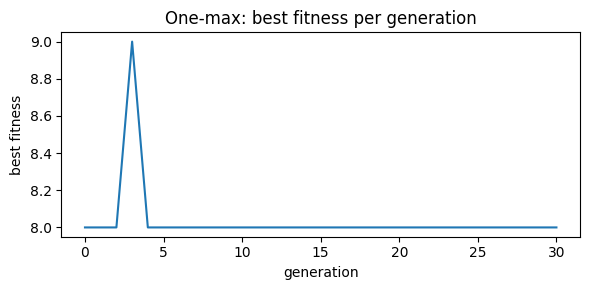

In [9]:
archive = Archive(DATABASE)
first_generation, last_generation = archive.generation_range
curve = [
    archive
    .by_generation(g)
    .best(sort="max", attribute="fitness_")
    .to_list()[0]
    .fitness
    for g in range(first_generation, last_generation + 1)
]
plt.figure(figsize=(6, 3))
plt.plot(range(first_generation, last_generation + 1), curve)
plt.xlabel("generation")
plt.ylabel("best fitness")
plt.title("One-max: best fitness per generation")
plt.tight_layout()
plt.show()
assert curve[-1] >= curve[0]
assert curve[-1] >= GENES - 2

In [10]:
fame = archive.hall_of_fame(n=HALL_SIZE, fitness_mode="max")
table = Table(title="Hall of fame")
for column in ("fitness", "genotype", "born"):
    table.add_column(column)
for individual in fame:
    table.add_row(
        f"{individual.fitness:g}",
        "".join(str(g) for g in individual.genotype),
        str(individual.time_of_birth),
    )
console.print(table)
assert len(fame) == HALL_SIZE
assert fame[0].fitness == max(curve)

         Hall of fame          
┏━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ fitness ┃ genotype   ┃ born ┃
┡━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ 9       │ 1111111101 │ 3    │
│ 8       │ 1111111010 │ 0    │
│ 7       │ 1010111101 │ 0    │
└─────────┴────────────┴──────┘

## Restart from the database

Passing `restart=` resumes from the latest recorded generation: the engine copies the individuals that were alive then and continues counting from the next generation. It writes a **new** database, so give it its own path.

In [11]:
generation_before = ea.current_generation
RESUMED_STEPS = 5
RESUMED = DATA / "resumed.db"
resumed = EA(
    None,
    operations,
    restart=DATABASE,
    num_steps=RESUMED_STEPS,
    db_file_path=RESUMED,
    quiet=True,
)
resumed.run()
console.print(f"generation {generation_before} -> {resumed.current_generation}")
assert RESUMED.is_file()
assert resumed.current_generation >= generation_before + RESUMED_STEPS
assert Archive(RESUMED).size >= POPULATION_SIZE

Output()

generation 30 -> 36